# Coding part for assignment 2 in Statistical Machine Learning

**Name**: Christian Ulrik Niekrenz \
**StudentID**: 21435375

In [99]:
# Imports
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize)
from ISLP import confusion_table
from ISLP.models import contrast
from sklearn.discriminant_analysis import \
    (LinearDiscriminantAnalysis as LDA,
     QuadraticDiscriminantAnalysis as QDA)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

## 4.13

### (a)

In [100]:
# Load data
Weekly = load_data("Weekly")
Weekly.head()

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
0,1990,0.816,1.572,-3.936,-0.229,-3.484,0.154976,-0.270,Down
1,1990,-0.270,0.816,1.572,-3.936,-0.229,0.148574,-2.576,Down
2,1990,-2.576,-0.270,0.816,1.572,-3.936,0.159837,3.514,Up
3,1990,3.514,-2.576,-0.270,0.816,1.572,0.161630,0.712,Up
4,1990,0.712,3.514,-2.576,-0.270,0.816,0.153728,1.178,Up


In [101]:
type(Weekly)

pandas.DataFrame

First we will have a look at the distribution of the return for the `lag1,...,5` given that the `direction` is either up or down, to figure out if there is any clear relationship here.

Based on these conditional histograms, there is no direct conclusion as to whether or not `lag1,...,5` are correlated with the direction of today's movement.

Text(0.5, 0.98, 'Lag return distributions by current market direction')

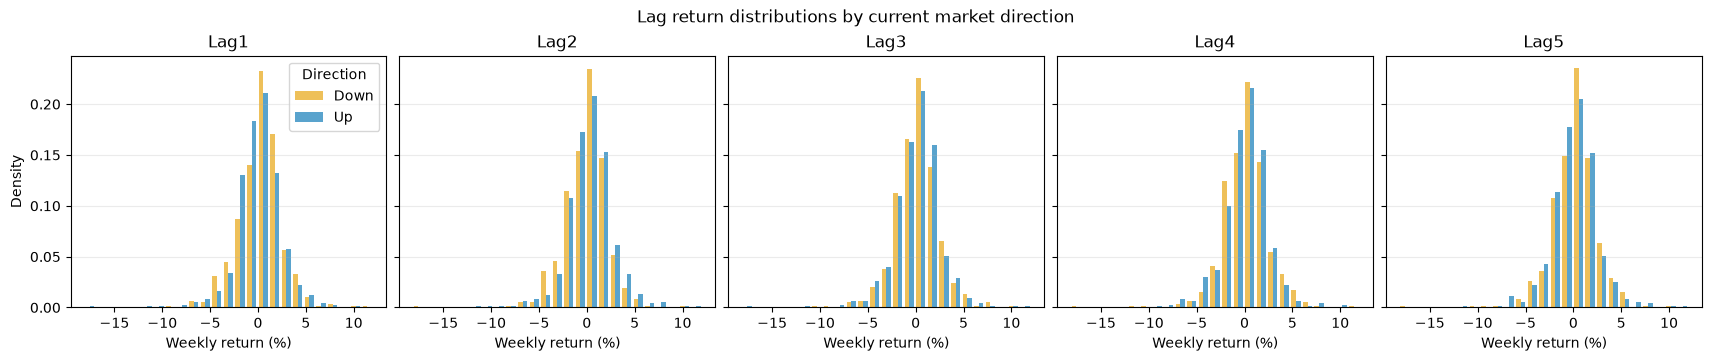

In [102]:
# Compare the distributions of each lag for weeks that went Up or Down
lags = [f"Lag{i}" for i in range(1, 6)]
directions = ["Down", "Up"]
colors = {"Down": "#E69F00", "Up": "#0072B2"}

fig, axes = subplots(1, 5, figsize=(17, 3.5), sharey=True, constrained_layout=True)
for ax, lag in zip(axes, lags):
    lag_by_direction = [
        Weekly.loc[Weekly["Direction"] == direction, lag]
        for direction in directions
    ]
    ax.hist(
        lag_by_direction,
        bins=25,
        density=True,
        alpha=0.65,
        color=[colors[direction] for direction in directions],
        label=directions,
    )
    ax.set_title(lag)
    ax.set_xlabel("Weekly return (%)")
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Density")
axes[0].legend(title="Direction")
fig.suptitle("Lag return distributions by current market direction")

Let's have a look at the correlation between the different features, the surrogate target `Direction`, and today's actual return. This can be seen in the matrix below. It also tells the same story: no direct correlation between the features and the target.

,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction (Up=1)
Lag1,1.00,-0.07,0.06,-0.07,-0.01,-0.06,-0.08,-0.05
Lag2,-0.07,1.00,-0.08,0.06,-0.07,-0.09,0.06,0.07
Lag3,0.06,-0.08,1.00,-0.08,0.06,-0.07,-0.07,-0.02
Lag4,-0.07,0.06,-0.08,1.00,-0.08,-0.06,-0.01,-0.02
Lag5,-0.01,-0.07,0.06,-0.08,1.00,-0.06,0.01,-0.02
Volume,-0.06,-0.09,-0.07,-0.06,-0.06,1.00,-0.03,-0.02
Today,-0.08,0.06,-0.07,-0.01,0.01,-0.03,1.00,0.72
Direction (Up=1),-0.05,0.07,-0.02,-0.02,-0.02,-0.02,0.72,1.00


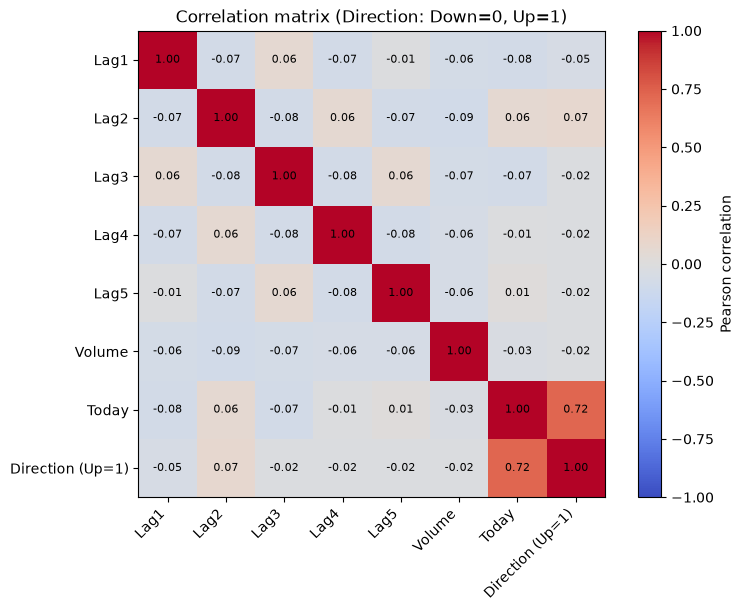

In [103]:
# Correlation matrix for lag returns, volume, today's return, and direction
lags = [f"Lag{i}" for i in range(1, 6)]

correlation_data = Weekly[lags + ["Volume", "Today"]].copy()
correlation_data["Direction (Up=1)"] = Weekly["Direction"].map(
    {"Down": 0, "Up": 1}
)

correlation_matrix = correlation_data.corr()

fig, ax = subplots(figsize=(8, 6), constrained_layout=True)
image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_xticklabels(correlation_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlation_matrix.index)))
ax.set_yticklabels(correlation_matrix.index)

for row in range(len(correlation_matrix.index)):
    for column in range(len(correlation_matrix.columns)):
        ax.text(
            column,
            row,
            f"{correlation_matrix.iloc[row, column]:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=8,
        )

ax.set_title("Correlation matrix (Direction: Down=0, Up=1)")
fig.colorbar(image, ax=ax, label="Pearson correlation")

correlation_matrix.round(2)

### (b)

Let's fit the logistic regression using the statsmodels library:

In [104]:
predictors = ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]

X = MS(predictors).fit_transform(Weekly)
y = Weekly["Direction"] == "Up"

weekly_glm = sm.GLM(y, X, family=sm.families.Binomial())
weekly_results = weekly_glm.fit()

summarize(weekly_results)

,coef,std err,z,P>|z|
intercept,0.2669,0.086,3.106,0.002
Lag1,-0.0413,0.026,-1.563,0.118
Lag2,0.0584,0.027,2.175,0.030
Lag3,-0.0161,0.027,-0.602,0.547
Lag4,-0.0278,0.026,-1.050,0.294
Lag5,-0.0145,0.026,-0.549,0.583
Volume,-0.0227,0.037,-0.616,0.538


Yes, in this full model, `Lag2` is statistically significant with a p-value of $0.03$, at the threshold of $\alpha=0.05$.

### (c)

Based on (b), we now create a confusion matrix on the training data.

In [105]:
predicted = np.where(weekly_results.predict(X) >= 0.5, "Up", "Down")
cm = confusion_table(predicted, Weekly["Direction"])
cm

Truth,Down,Up
Predicted,,
Down,54,48
Up,430,557


The model predicts correctly in $56.1\%$ of cases.

In [106]:
(predicted == Weekly["Direction"].to_numpy()).mean()

np.float64(0.5610651974288338)

When we have a classification task, we can compare the predicted classes with the actual classes, which is exactly what the confusion matrix does. From it we can calculate the proportion of the positive class (Up) that is predicted correctly and the proportion that is not, and the same for the negative class.

In [107]:
TN = cm.loc["Down", "Down"]
FN = cm.loc["Down", "Up"]
FP = cm.loc["Up", "Down"]
TP = cm.loc["Up", "Up"]

FPR = FP / (FP + TN)
TPR = TP / (TP + FN)
FNR = FN / (FN + TP)
TNR = TN / (TN + FP)

print(f"FPR: {FPR:.3f}")
print(f"TPR: {TPR:.3f}")
print(f"FNR: {FNR:.3f}")
print(f"TNR: {TNR:.3f}")

FPR: 0.888
TPR: 0.921
FNR: 0.079
TNR: 0.112


Here we see that the TPR is high, meaning that it predicts `Up` correctly most of the time, but also that the FPR is high. This is because the model mostly just predicts `Up` for all rows.

### (d)

In [108]:
train = Weekly[Weekly["Year"] <= 2008]
test = Weekly[Weekly["Year"] >= 2009]

X_train = MS(["Lag2"]).fit_transform(train)
X_test = MS(["Lag2"]).fit_transform(test)
y_train = train["Direction"] == "Up"

lag2_model = sm.GLM(
    y_train,
    X_train,
    family=sm.families.Binomial()
).fit()

predicted = np.where(lag2_model.predict(X_test) >= 0.5, "Up", "Down")

confusion_table(predicted, test["Direction"])

Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


Above we have the confusion matrix, with the same problem as the previous model. The overall correct prediction rate is $62.5\%$, which is better than before and also on unseen data.

In [109]:
(predicted == test["Direction"].to_numpy()).mean()

np.float64(0.625)

### (e), (f), (g), (h)

Using the same data as from (d), and running all the four models in a loop,

In [110]:
X_train_lag2 = train[["Lag2"]]
X_test_lag2 = test[["Lag2"]]
y_train = train["Direction"]

classifiers = {
    "LDA": LDA(),
    "QDA": QDA(),
    "KNN (K=1)": KNeighborsClassifier(n_neighbors=1),
    "Naive Bayes": GaussianNB(),
}

predictions = {}

for name, classifier in classifiers.items():
    classifier.fit(X_train_lag2, y_train)
    predictions[name] = classifier.predict(X_test_lag2)

    print(f"\n{name} confusion matrix (rows: predicted; columns: actual)")
    print(confusion_table(predictions[name], test["Direction"]))


LDA confusion matrix (rows: predicted; columns: actual)
Truth      Down  Up
Predicted          
Down          9   5
Up           34  56

QDA confusion matrix (rows: predicted; columns: actual)
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61

KNN (K=1) confusion matrix (rows: predicted; columns: actual)
Truth      Down  Up
Predicted          
Down         22  31
Up           21  30

Naive Bayes confusion matrix (rows: predicted; columns: actual)
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61


In [111]:
accuracy_table = pd.DataFrame({
    "Model": list(predictions.keys()),
    "Correct Predictions": [
        (predictions[name] == test["Direction"].to_numpy()).sum()
        for name in predictions
    ],
    "Accuracy": [
        (predictions[name] == test["Direction"].to_numpy()).mean()
        for name in predictions
    ],
})

accuracy_table["Accuracy"] = accuracy_table["Accuracy"].map("{:.1%}".format)
accuracy_table

,Model,Correct Predictions,Accuracy
0,LDA,65,62.5%
1,QDA,61,58.7%
2,KNN (K=1),52,50.0%
3,Naive Bayes,61,58.7%


### (i)

LDA and logistic regression both give the same accuracy on the test data, and the highest of all the models.

### (j)

I came up with 20 different feature combinations and tried all of them on the different models. Also, since KNN is the only one with a hyperparameter, we also tried different K values for all the feature combinations.

In [112]:
def make_features(data, names):
    values = {
        **{
            col: data[col]
            for col in [f"Lag{i}" for i in range(1, 6)] + ["Volume"]
        },
        "Lag1^2": data["Lag1"] ** 2,
        "Lag2^2": data["Lag2"] ** 2,
        "Lag3^2": data["Lag3"] ** 2,
        "Lag4^2": data["Lag4"] ** 2,
        "Lag5^2": data["Lag5"] ** 2,
        "Lag2^3": data["Lag2"] ** 3,
        "|Lag2|": data["Lag2"].abs(),
        "Lag1*Lag2": data["Lag1"] * data["Lag2"],
        "Lag2*Lag3": data["Lag2"] * data["Lag3"],
        "Lag3*Lag4": data["Lag3"] * data["Lag4"],
        "Lag4*Lag5": data["Lag4"] * data["Lag5"],
        "Lag2*Volume": data["Lag2"] * data["Volume"],
        "Volume^2": data["Volume"] ** 2,
    }
    return pd.DataFrame(
        {name: values[name] for name in names},
        index=data.index,
    )


feature_sets = {
    "01 Lag2": ["Lag2"],
    "02 Lag1 + Lag2": ["Lag1", "Lag2"],
    "03 Lag2 + Lag3": ["Lag2", "Lag3"],
    "04 Lag1-Lag3": ["Lag1", "Lag2", "Lag3"],
    "05 All five lags": ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5"],
    "06 All lags + Volume": ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"],
    "07 Lag2 + Volume": ["Lag2", "Volume"],
    "08 Lag1 + Lag2 + Volume": ["Lag1", "Lag2", "Volume"],
    "09 Lag2 + Lag4": ["Lag2", "Lag4"],
    "10 Odd lags": ["Lag1", "Lag3", "Lag5"],
    "11 Lag2 + square": ["Lag2", "Lag2^2"],
    "12 Lag2 + cube": ["Lag2", "Lag2^3"],
    "13 Lag2 + absolute value": ["Lag2", "|Lag2|"],
    "14 Lag1 + Lag2 + interaction": ["Lag1", "Lag2", "Lag1*Lag2"],
    "15 Lag1 + Lag2 + squares": ["Lag1", "Lag2", "Lag1^2", "Lag2^2"],
    "16 Lags 1-3 + interaction": ["Lag1", "Lag2", "Lag3", "Lag1*Lag2"],
    "17 Lag2 + Volume + interaction": ["Lag2", "Volume", "Lag2*Volume"],
    "18 Lag2 + Volume + squares": ["Lag2", "Volume", "Lag2^2", "Volume^2"],
    "19 All lags + squares": [
        "Lag1", "Lag2", "Lag3", "Lag4", "Lag5",
        "Lag1^2", "Lag2^2", "Lag3^2", "Lag4^2", "Lag5^2",
    ],
    "20 All lags + interactions": [
        "Lag1", "Lag2", "Lag3", "Lag4", "Lag5",
        "Lag1*Lag2", "Lag2*Lag3", "Lag3*Lag4", "Lag4*Lag5",
    ],
}

non_knn_models = {
    "Logistic regression": LogisticRegression(max_iter=2000),
    "LDA": LDA(),
    "QDA": QDA(),
    "Naive Bayes": GaussianNB(),
}

records = []
actual = test["Direction"].to_numpy()

for feature_set, feature_names in feature_sets.items():
    X_train_features = make_features(train, feature_names)
    X_test_features = make_features(test, feature_names)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_features)
    X_test_scaled = scaler.transform(X_test_features)

    for method, model in non_knn_models.items():
        model.fit(X_train_scaled, train["Direction"])
        predicted = model.predict(X_test_scaled)

        records.append({
            "Method": method,
            "Predictors": feature_set,
            "K": "-",
            "Accuracy": (predicted == actual).mean(),
            "Predicted": predicted,
        })

    for k in [1, 3, 5, 10, 20, 50]:
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(X_train_scaled, train["Direction"])
        predicted = model.predict(X_test_scaled)

        records.append({
            "Method": "KNN",
            "Predictors": feature_set,
            "K": k,
            "Accuracy": (predicted == actual).mean(),
            "Predicted": predicted,
        })

leaderboard = pd.DataFrame([
    {
        "Method": result["Method"],
        "Predictors": result["Predictors"],
        "K": result["K"],
        "Accuracy": result["Accuracy"],
    }
    for result in records
]).sort_values("Accuracy", ascending=False)

display(leaderboard.head(10).style.format({"Accuracy": "{:.1%}"}))

best = max(records, key=lambda result: result["Accuracy"])
print(
    f"Best: {best['Method']} | {best['Predictors']} | "
    f"K={best['K']} | Accuracy={best['Accuracy']:.1%}"
)
print("Confusion matrix (rows: predicted; columns: actual):")
print(confusion_table(best["Predicted"], test["Direction"]))

,Method,Predictors,K,Accuracy
142,QDA,15 Lag1 + Lag2 + squares,-,64.4%
0,Logistic regression,01 Lag2,-,62.5%
21,LDA,03 Lag2 + Lag3,-,62.5%
1,LDA,01 Lag2,-,62.5%
80,Logistic regression,09 Lag2 + Lag4,-,62.5%
102,QDA,11 Lag2 + square,-,62.5%
81,LDA,09 Lag2 + Lag4,-,62.5%
20,Logistic regression,03 Lag2 + Lag3,-,62.5%
110,Logistic regression,12 Lag2 + cube,-,62.5%
100,Logistic regression,11 Lag2 + square,-,62.5%


Best: QDA | 15 Lag1 + Lag2 + squares | K=- | Accuracy=64.4%
Confusion matrix (rows: predicted; columns: actual):
Truth      Down  Up
Predicted          
Down         20  14
Up           23  47


In this case, the only model better than logistic regression and LDA is a QDA with features "Lag1 + Lag2 + squares", where both features are squared.

## 4.14

### (a)

In [113]:
Auto = load_data("Auto")
Auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
name,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1
ford torino,17.0,8,302.0,140,3449,10.5,70,1


Let's create the surrogate 0-1 variable `mpg01`.

In [ ]:
Auto["mpg01"] = (Auto["mpg"] > Auto["mpg"].median()).astype(int)
Auto["mpg"].median()

In [115]:
Auto[["mpg","mpg01"]].head()

,mpg,mpg01
name,,
chevrolet chevelle malibu,18.0,0
buick skylark 320,15.0,0
plymouth satellite,18.0,0
amc rebel sst,16.0,0
ford torino,17.0,0


### (b)

Let's make stratified boxplots for each of the features, based on the value of `mpg01`.

In [ ]:
features = [
    column
    for column in Auto.select_dtypes(include=np.number).columns
    if column not in ["mpg", "mpg01", "origin"]
]

ncols = 2
nrows = (len(features) + ncols - 1) // ncols

fig, axes = subplots(
    nrows,
    ncols,
    figsize=(13, 3.2 * nrows),
    sharex=True,
    constrained_layout=True,
)
axes = np.asarray(axes).ravel()

group_colors = ["#0072B2", "#E69F00"]

for ax, feature in zip(axes, features):
    groups = [
        Auto.loc[Auto["mpg01"] == group, feature].dropna()
        for group in [0, 1]
    ]

    boxplot = ax.boxplot(
        groups,
        patch_artist=True,
        showfliers=False,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "#333333",
            "markersize": 5,
        },
        medianprops={"color": "#222222", "linewidth": 2},
        whiskerprops={"color": "#555555"},
        capprops={"color": "#555555"},
    )

    for patch, color in zip(boxplot["boxes"], group_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.set_title(feature, loc="left", fontweight="bold")
    ax.set_ylabel("Value")
    ax.set_xticks([1, 2], ["Below median MPG", "At/above median MPG"])
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

for ax in axes[len(features):]:
    ax.set_visible(False)

fig.suptitle(
    "Auto features grouped by MPG category",
    fontsize=16,
    fontweight="bold",
)

I would say `cylinders`, `displacement`, `weight` and `horsepower` all look like strong predictors, since their marginal conditional distributions look different.

### (c)

In [117]:
train, test = train_test_split(Auto, test_size=0.2, random_state=0)

### (d)

We perform LDA, which gives a test error of $0.139$.

In [118]:
predictors = ["cylinders", "displacement", "horsepower", "weight"]

X_train, y_train = train[predictors], train["mpg01"]
X_test, y_test = test[predictors], test["mpg01"]

lda = LDA().fit(X_train, y_train)
pred = lda.predict(X_test)

print(confusion_table(pred, y_test))
test_error = (pred != y_test).mean()
print(f"Test error: {test_error:.3f}")

Truth       0   1
Predicted        
0          34   3
1           8  34
Test error: 0.139


### (e), (f), (g), (h)

Since all the models use the same data and are evaluated the same way, we fit them all in one loop.

In [119]:
models = {
    "LDA (d)": LDA(),
    "QDA (e)": QDA(),
    "Logistic (f)": LogisticRegression(max_iter=1000),
    "Naive Bayes (g)": GaussianNB(),
}
for k in [1, 3, 5, 7, 9, 11, 15, 21, 31]:
    models[f"KNN K={k} (h)"] = KNeighborsClassifier(n_neighbors=k)

errors = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    errors[name] = (model.predict(X_test) != y_test).mean()
    print(f"{name:<18} test error = {errors[name]:.3f}")

knn_errors = {name: err for name, err in errors.items() if name.startswith("KNN")}
best_knn = min(knn_errors, key=knn_errors.get)
print(f"\nBest KNN: {best_knn} (test error {knn_errors[best_knn]:.3f})")

LDA (d)            test error = 0.139
QDA (e)            test error = 0.139
Logistic (f)       test error = 0.127
Naive Bayes (g)    test error = 0.127
KNN K=1 (h)        test error = 0.114
KNN K=3 (h)        test error = 0.101
KNN K=5 (h)        test error = 0.152
KNN K=7 (h)        test error = 0.152
KNN K=9 (h)        test error = 0.165
KNN K=11 (h)       test error = 0.165
KNN K=15 (h)       test error = 0.177
KNN K=21 (h)       test error = 0.177
KNN K=31 (h)       test error = 0.177

Best KNN: KNN K=3 (h) (test error 0.101)


The best overall model, in terms of test error, is KNN with K = 3.

## 5.5

### (a)

First, let's fit the model on all the data:

In [120]:
np.random.seed(0)

Default = load_data("Default")
Default["student"] = (Default["student"] == "Yes").astype(int)
y = (Default["default"] == "Yes").astype(int)

full_fit = sm.GLM(y, MS(["income", "balance"]).fit_transform(Default), family=sm.families.Binomial()).fit()
full_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                default   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9997
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -789.48
Date:                Fri, 23 Oct 2026   Deviance:                       1579.0
Time:                        16:26:45   Pearson chi2:                 6.95e+03
No. Iterations:                     9   Pseudo R-squ. (CS):             0.1256
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    -11.5405      0.435    -26.544      0.000     -12.393     -10.688
income      2.081e-05   4.99e-06      4.174      0.000     1.1e-05    3.06e-05
balance        0.0056      0.000     24.835      0.000       0.005       0.006
==============================================================================
"""

### (b)

Now let's create a function that takes a seed for the random split into training and validation sets. This function is reused in the later parts.

In [121]:
def val_error(cols, seed):
    train, valid = train_test_split(Default, test_size=0.5, random_state=seed)
    fit = sm.GLM(y[train.index], MS(cols).fit_transform(train), family=sm.families.Binomial()).fit()
    prob = fit.predict(MS(cols).fit_transform(valid))
    return ((prob > 0.5).astype(int) != y[valid.index]).mean()

In [122]:
val_error(["income", "balance"], 0)

np.float64(0.029)

### (c)

We now run the function with three different seeds.

In [123]:
for seed in [1, 2, 3]:
    print(seed, val_error(["income", "balance"], seed))

1 0.025
2 0.0248
3 0.0248


### (d)

Let's now include the `student` variable and fit the model with three different splits.

In [124]:
for seed in [1, 2, 3]:
    print(seed, val_error(["income", "balance", "student"], seed))

1 0.0262
2 0.0254


3 0.0252


In general, it looks like including the `student` variable does not help, since the validation error increases on average.

## 5.6

### (a)

We start off by just fitting the logistic regression, and using the summary to get the standard error of the estimates.

In [125]:
design = MS(["income", "balance"]).fit_transform(Default)
glm_fit = sm.GLM(y, design, family=sm.families.Binomial()).fit()
summarize(glm_fit)

,coef,std err,z,P>|z|
intercept,-11.540500,0.435000,-26.544,0.0
income,0.000021,0.000005,4.174,0.0
balance,0.005600,0.000000,24.835,0.0


### (b)

We write the `boot_fn()` function. It takes in the data and an array of row indices, fits the model on those rows, and returns the income and balance coefficients.

In [ ]:
def boot_fn(D, idx):
    D_ = D.loc[idx]
    X = MS(["income", "balance"]).fit_transform(D_)
    y_ = (D_["default"] == "Yes").astype(int)
    fit = sm.GLM(y_, X, family=sm.families.Binomial()).fit()
    return fit.params[["income", "balance"]]

### (c)

We now use the function from (b) to perform the bootstrap and a number of bootstrap samples, to get an estimate of the standard error.

In [ ]:
def boot_SE(func, D, n=None, B=1000, seed=0):
    rng = np.random.default_rng(seed)
    first_, second_ = 0, 0
    n = n or D.shape[0]
    for _ in range(B):
        idx = rng.choice(D.index, n, replace=True)
        value = func(D, idx)
        first_ += value
        second_ += value ** 2
    return np.sqrt(second_ / B - (first_ / B) ** 2)

boot_se = boot_SE(boot_fn, Default, B=1000, seed=0)
boot_se

### (d)

They are very similar.

In [ ]:
pd.DataFrame({"GLM SE": glm_fit.bse[["income", "balance"]], "bootstrap SE": boot_se})